In [11]:
import torch

In [12]:
adjacency_list_old = [
    (1, 5), (2, 5), (3, 5), # Feed to S5
    (1, 6), (2, 6), (3, 6), # Feed to S6
    (4, 15), (4, 16), (4, 17), (4, 18), # Feed to stripper
    # Reactor
    (6, 7), (6, 8), (6, 9), (6, 21),
    (7, 22), (7, 11), (7, 12), (7, 13),
    # Reactor T, P and Level to separator and condenser
    (8, 22), (8, 11), (8, 12), (8, 13),
    (9, 22), (9, 11), (9, 12), (9, 13),
    (22, 11), (22, 12), (22, 13),
    # Separator T, P and level to recycle stream
    (11, 10), (11, 5), (11, 6),
    (12, 10), (12, 5), (12, 6),
    (13, 10), (13, 5), (13, 6),
    # Separator T, P and level to stripper
    (11, 14), (11, 15), (11, 16), (11, 17), (11, 18), (11, 19),
    (12, 14), (12, 15), (12, 16), (12, 17), (13, 18), (12, 19),
    (13, 14), (13, 15), (13, 16), (12, 17), (13, 18), (12, 19),
    # Stripper recycle
    (19, 15), (19, 16), (19, 17), (19, 18),
]

In [13]:
adjacency_list = [
    # feeds, recycle, stripper overhead -> reactor feed
    (1,6),(2,6),(3,6),(5,6),(16,6),(18,6),
    # C feed -> stripper
    (4,15),(4,16),(4,18),
    # reactor feed -> reactor, reactor internals, cooling jacket
    (6,7),(6,8),(6,9),(7,8),(7,9),(8,9),(9,21),
    # reactor -> condenser -> separator
    (9,22),(22,11),(7,13),
    # separator internals
    (11,12),(11,13),(12,13),
    # separator vapour -> compressor / recycle / purge
    (13,20),(13,5),(13,10),(20,5),(20,10),(5,10),
    # separator liquid -> underflow -> stripper
    (12,14),(13,14),(14,15),(14,16),(14,18),
    # stripper internals, steam, product
    (15,16),(15,18),(16,18),(15,17),(18,19),(16,19),
]    # undirected

In [14]:
adjacency_list_actuators = [
    # feeds, recycle, stripper overhead -> reactor feed
    (1,6),(2,6),(3,6),(5,6),(16,6),(18,6),
    # C feed -> stripper
    (4,15),(4,16),(4,18),
    # reactor feed -> reactor, reactor internals, cooling jacket
    (6,7),(6,8),(6,9),(7,8),(7,9),(8,9),(9,21),
    # reactor -> condenser -> separator
    (9,22),(22,11),(7,13),
    # separator internals
    (11,12),(11,13),(12,13),
    # separator vapour -> compressor / recycle / purge
    (13,20),(13,5),(13,10),(20,5),(20,10),(5,10),
    # separator liquid -> underflow -> stripper
    (12,14),(13,14),(14,15),(14,16),(14,18),
    # stripper internals, steam, product
    (15,16),(15,18),(16,18),(15,17),(18,19),(16,19),

    # --- actuators (valve -> sensor on the same line) ---
    (23,2),                # XMV1  D feed valve        -> S2
    (24,3),                # XMV2  E feed valve        -> S3
    (25,1),                # XMV3  A feed valve        -> S1
    (26,4),                # XMV4  A+C feed valve      -> S4
    (27,5),(27,20),        # XMV5  compressor recycle  -> S5, S20
    (28,10),               # XMV6  purge valve         -> S10
    (29,14),               # XMV7  separator liquid    -> S14
    (30,17),               # XMV8  stripper product    -> S17
    (31,19),               # XMV9  stripper steam      -> S19
    (32,21),               # XMV10 reactor CW          -> S21
    (33,22),               # XMV11 condenser CW        -> S22
]    # undirected, 1-indexed (subtract 1 for PyG)

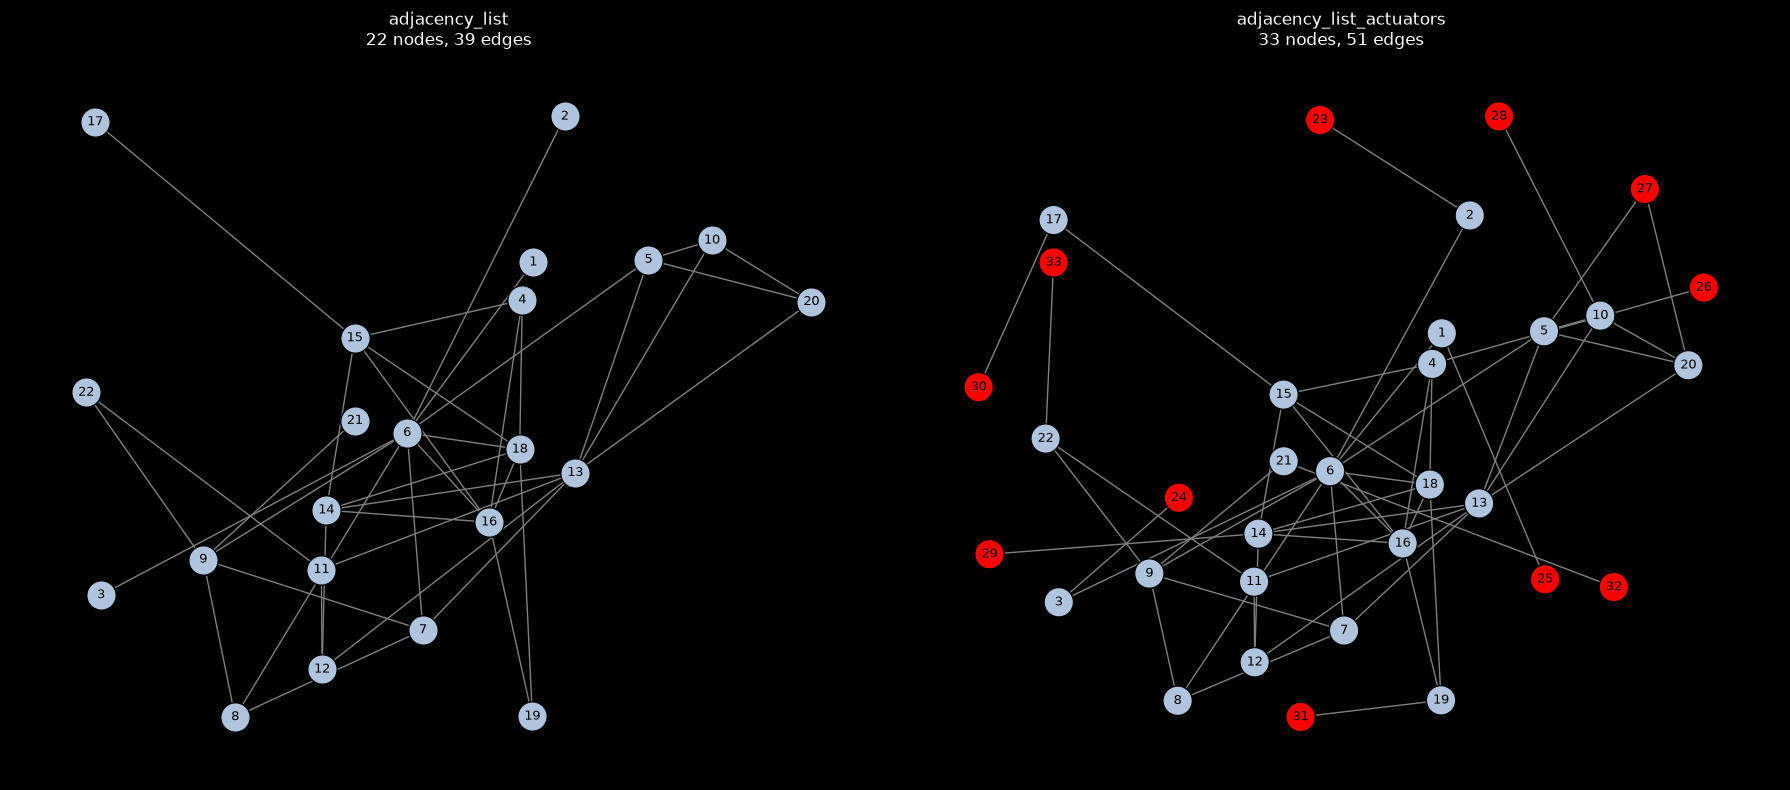

In [18]:
import networkx as nx
import matplotlib.pyplot as plt

def build_graph(edges):
    G = nx.Graph()          # undirected, consistent with the edge_index construction
    G.add_edges_from(edges)
    return G

graphs = {
    # "adjacency_list_old": build_graph(adjacency_list_old),
    "adjacency_list": build_graph(adjacency_list),
    "adjacency_list_actuators": build_graph(adjacency_list_actuators)
}

# Use one shared set of node positions so the two graphs are directly comparable
all_nodes = sorted(set().union(*(g.nodes for g in graphs.values())))
union_graph = nx.Graph()
union_graph.add_nodes_from(all_nodes)
for g in graphs.values():
    union_graph.add_edges_from(g.edges)
pos = nx.spring_layout(union_graph, seed=42, k=0.9)

fig, axes = plt.subplots(1, 2, figsize=(18, 8))
for ax, (name, g) in zip(axes, graphs.items()):
    if name == "adjacency_list_actuators":
        node_color = ["red" if n >= 23 else "lightsteelblue" for n in g.nodes]
    else:
        node_color = "lightsteelblue"
    nx.draw_networkx(
        g, pos, ax=ax, with_labels=True,
        node_color=node_color, edgecolors="k", node_size=450,
        font_size=9, edge_color="gray", width=1.0,
    )
    ax.set_title(f"{name}\n{g.number_of_nodes()} nodes, {g.number_of_edges()} edges")
    ax.axis("off")
plt.tight_layout()
plt.show()